# E-commerce Product Classification Using NLP

**Objective.** Build and evaluate an NLP pipeline that assigns an e-commerce product description to one of four categories using the text alone:

1. Electronics
2. Household
3. Books
4. Clothing & Accessories

**Method.** Product descriptions are converted to numerical vectors with **TF-IDF** and classified with three models: **Multinomial Naive Bayes**, **Logistic Regression** and **Linear Support Vector Machine (LinearSVC)**. The models are compared on one shared, stratified 80/20 train-test split, mainly with the **macro-averaged F1-score**.

**Dataset.** *E-commerce Text Classification* (Kaggle: `saurabhshahane/ecommerce-text-classification`, file `ecommerceDataset.csv`). The reference notebook for this assignment is `sugataghosh/e-commerce-text-classification-tf-idf-word2vec`.

> All numbers, tables and figures in this notebook are produced by the code cells when they run. No result is typed in by hand.

## 0. Setup
The cell below makes the project modules importable and sets common options. The notebook works when started from the project root or from the `notebooks/` folder.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

import config
from src import data_loader, evaluate, predict, preprocessing, train

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 150)
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_SEED = config.RANDOM_SEED
RUN_CV = True   # set to False to skip the (slower) cross-validation section
print("Project root:", ROOT)

Project root: /home/claude/ecommerce-product-classification


## 1. Dataset Loading
`data_loader.load_dataset` reads the CSV file, detects whether it has a header row, and detects the text and label columns. The original Kaggle file has **no header**: the first column is the category and the second column is the product description. If the dataset is missing, the cell stops with instructions (`python main.py --download` or a manual download into `data/`).

In [2]:
data_path = data_loader.find_dataset()
if data_path is None:
    raise SystemExit(data_loader.missing_dataset_message())

raw_df, TEXT_COL, LABEL_COL = data_loader.load_dataset(data_path)
print(f"File          : {data_path.name}")
print(f"Text column   : '{TEXT_COL}'")
print(f"Label column  : '{LABEL_COL}'")

File          : ecommerceDataset.csv
Text column   : 'text'
Label column  : 'label'


## 2. Data Exploration
First we inspect the raw data: the first rows, the shape, the column names, the data types and summary statistics.

In [3]:
display(raw_df.head(5).assign(text=lambda d: d[TEXT_COL].astype(str).str.slice(0, 150) + " ..."))
print("Shape         :", raw_df.shape)
print("Column names  :", list(raw_df.columns))
print("\nData types:")
display(raw_df.dtypes.to_frame("dtype"))
print("Summary statistics:")
display(raw_df.describe(include="all"))

,label,text
0,Household,Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting mad...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x 10 inch, Special Effect UV Print Textured, SAO297) Painting made up in..."
2,Household,"SAF 'UV Textured Modern Art Print Framed' Painting (Synthetic, 35 cm x 50 cm x 3 cm, Set of 3) Color:Multicolor ..."
3,Household,"SAF Flower Print Framed Painting (Synthetic, 13.5 inch x 22 inch, UV Textured, Set of 3, SANFSW4951) Color:Multicolo..."
4,Household,Incredible Gifts India Wooden Happy Birthday Unique Personalized Gift (5 X 4 Inch) Size:4 x 5 Made Of Natural Impo...


Shape         : (50425, 2)
Column names  : ['label', 'text']

Data types:


,dtype
label,str
text,str


Summary statistics:


,label,text
count,50425,50424
unique,4,27802
top,Household,"Think & Grow Rich About the Author NAPOLEON HILL, born in Pound, Southwest Virginia in 1883, was a very successful A..."
freq,19313,30


## 3. Missing Values and Duplicate Analysis
Missing descriptions or labels cannot be used for supervised learning and are removed. **Exact duplicate records** (same category and same text) are also removed. This is justified because duplicates carry no new information and, more importantly, an identical record could land in both the training and the test set. The model would then be tested on text it has already seen, which makes the test score look better than it really is (data leakage).

In [4]:
overview = preprocessing.dataset_overview(raw_df)
missing = pd.DataFrame({"missing values": overview["missing_per_column"]})
missing["percent"] = (100 * missing["missing values"] / len(raw_df)).round(4)
display(missing)

n_dup = overview["duplicate_rows"]
print(f"Exact duplicate rows: {n_dup:,} of {len(raw_df):,} ({100 * n_dup / len(raw_df):.1f}%)")

print("\nRows with a missing value:")
display(raw_df[raw_df.isna().any(axis=1)])

print("Raw class counts (before any cleaning):")
display(raw_df[LABEL_COL].value_counts().to_frame("samples"))

,missing values,percent
label,0,0.000
text,1,0.002


Exact duplicate rows: 22,622 of 50,425 (44.9%)

Rows with a missing value:


,label,text
39330,Clothing & Accessories,NaN


Raw class counts (before any cleaning):


,samples
label,
Household,19313
Books,11820
Electronics,10621
Clothing & Accessories,8671


## 4. Data Cleaning and Preprocessing
The text cleaner (`preprocessing.clean_text`) performs the following steps:

- decodes HTML entities and removes HTML tags, URLs and e-mail addresses;
- removes control characters and applies Unicode normalisation;
- converts to lowercase and removes apostrophes (`men's` becomes `mens`);
- replaces other punctuation by spaces and collapses repeated whitespace.

**Numbers and alphanumeric tokens are kept**, so technical terms such as `256gb`, `15` or `usb c` survive. Labels are never used as model input.

`prepare_dataframe` applies the whole preparation and **counts every removal**, so nothing is discarded silently.

In [5]:
samples = [
    "<p>Men's Slim-Fit T-Shirt &amp; Cap</p> Buy at https://shop.example.com/deal NOW!!!",
    "iPhone 15 Pro, 256GB (USB-C)   -   Bluetooth 5.3",
    None,
]
pd.DataFrame({"raw": samples, "cleaned": [preprocessing.clean_text(s) for s in samples]})

,raw,cleaned
0,<p>Men's Slim-Fit T-Shirt &amp; Cap</p> Buy at https://shop.example.com/deal NOW!!!,mens slim fit t shirt cap buy at now
1,"iPhone 15 Pro, 256GB (USB-C) - Bluetooth 5.3",iphone 15 pro 256gb usb c bluetooth 5 3
2,NaN,


In [6]:
df, data_report = preprocessing.prepare_dataframe(raw_df, TEXT_COL, LABEL_COL)

removals = pd.Series({
    "missing label": data_report["removed_missing_label"],
    "missing / blank description": data_report["removed_missing_text"],
    "unexpected label": data_report["removed_unexpected_label"],
    "exact duplicate records": data_report["removed_exact_duplicates"],
    "empty after cleaning": data_report["removed_empty_after_cleaning"],
    "duplicates after cleaning": data_report["removed_duplicates_after_cleaning"],
    "identical text, conflicting labels": data_report["removed_conflicting_labels"],
}, name="rows removed")
display(removals.to_frame())
print(f"Rows before: {data_report['rows_initial']:,}   rows after: {data_report['rows_final']:,}   "
      f"removed: {data_report['rows_removed_total']:,} ({data_report['percent_removed']}%)")
if data_report["missing_categories"]:
    print("WARNING - categories missing from the data:", data_report["missing_categories"])
if data_report["unexpected_labels"]:
    print("WARNING - unexpected labels removed:", data_report["unexpected_labels"])
LABELS = preprocessing.present_categories(df["label"])
print("Categories used:", LABELS)

,rows removed
missing label,0
missing / blank description,1
unexpected label,0
exact duplicate records,22622
empty after cleaning,0
duplicates after cleaning,93
"identical text, conflicting labels",0


Rows before: 50,425   rows after: 27,709   removed: 22,716 (45.05%)
Categories used: ['Electronics', 'Household', 'Books', 'Clothing & Accessories']


## 5. Class Distribution
The table and the chart show how many samples each of the four categories has **after** cleaning. Class imbalance matters: accuracy can look good if a large class dominates, which is why macro-averaged metrics are reported as well.

,samples,percent
label,,
Electronics,5302,19.13
Household,10558,38.10
Books,6202,22.38
Clothing & Accessories,5647,20.38


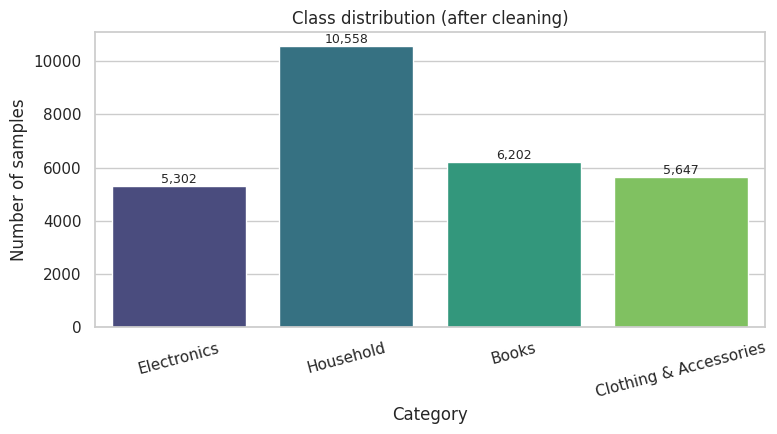

In [7]:
counts = df["label"].value_counts().reindex(LABELS)
dist = pd.DataFrame({"samples": counts, "percent": (100 * counts / counts.sum()).round(2)})
display(dist)
fig = evaluate.plot_class_distribution(counts, title="Class distribution (after cleaning)")
plt.show()

Text length statistics of the cleaned descriptions (words and characters):


characters                                                       words                                               
                            count   mean     std  min    25%    50%     75%      max    count   mean    std  min   25%    50%    75%     max
label                                                                                                                                       
Books                      6202.0  858.8  1766.6  3.0   77.0  459.0  1049.0  49220.0   6202.0  143.3  304.0  1.0  12.0   76.0  171.0  8427.0
Clothing & Accessories     5647.0  432.9   370.0  4.0  185.0  336.0   542.5   3404.0   5647.0   74.5   64.3  1.0  31.0   58.0   94.0   588.0
Electronics                5302.0  793.5   755.1  8.0  258.2  593.0  1150.8  11952.0   5302.0  136.7  128.8  1.0  45.0  102.0  198.8  2075.0
Household                 10558.0  637.9   560.9  8.0  266.0  499.5   857.0   9874.0  10558.0  109.2   96.0  1.0  45.0   85.0  147.0  1791.0

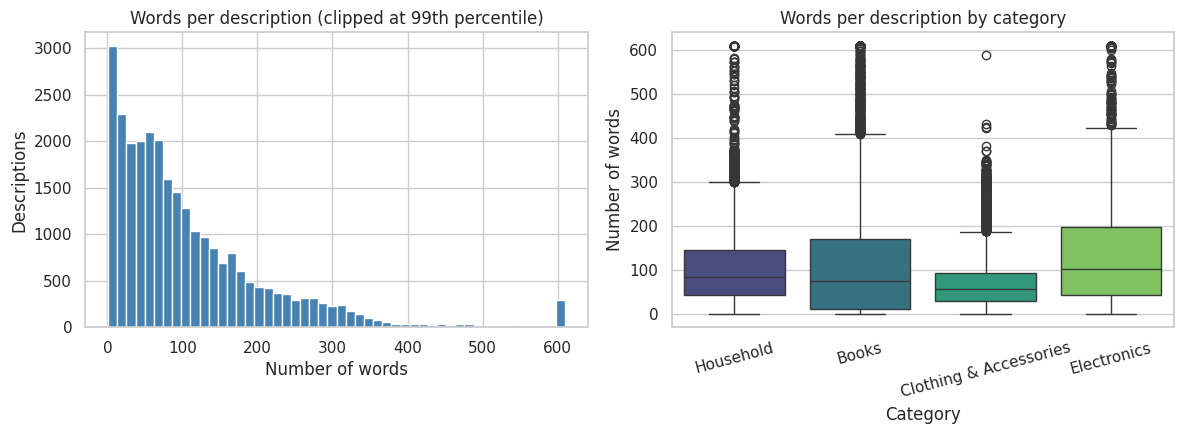

Overall words per description:


,words
count,27709.0
mean,115.0
std,169.8
min,1.0
25%,35.0
50%,78.0
75%,150.0
max,8427.0


In [8]:
print("Text length statistics of the cleaned descriptions (words and characters):")
display(preprocessing.text_statistics(df))
fig = evaluate.plot_text_length_distribution(df)
plt.show()
print("Overall words per description:")
display(df["clean_text"].str.split().str.len().describe().round(1).to_frame("words"))

## 6. Train-Test Split
The data is divided into **80% training** and **20% testing** with `train_test_split`. `stratify` keeps the class proportions the same in both parts, and a fixed `random_state` makes the split reproducible. The raw text is split; cleaning and TF-IDF are part of the pipeline and are therefore fitted on the training part only.

In [9]:
X_train, X_test, y_train, y_test = train.split_data(df, config.TEST_SIZE, RANDOM_SEED)
print(f"Training samples: {len(X_train):,}   Test samples: {len(X_test):,}   (seed = {RANDOM_SEED})")
pd.DataFrame({"train %": (100 * y_train.value_counts(normalize=True)).round(2),
              "test %": (100 * y_test.value_counts(normalize=True)).round(2)}).reindex(LABELS)

Training samples: 22,167   Test samples: 5,542   (seed = 42)


,train %,test %
label,,
Electronics,19.14,19.13
Household,38.10,38.11
Books,22.38,22.39
Clothing & Accessories,20.38,20.37


## 7. Text Representation with TF-IDF

**What is TF-IDF?** *Term Frequency - Inverse Document Frequency* gives every word in a document a weight. The **term frequency (TF)** says how often the word occurs in the document. The **inverse document frequency (IDF)** lowers the weight of words that occur in many documents (such as "product" or "quality") and raises the weight of rare, specific words (such as "paperback" or "bluetooth"). The weight of a term is roughly *TF x IDF*; scikit-learn additionally normalises each document vector to unit length.

**Why is it useful for product classification?** Category-specific words (*novel, author, stove, hdmi, cotton*) receive high weights, while generic words are down-weighted. The result is a sparse numerical vector that simple linear classifiers can use very effectively.

**Unigrams and bigrams.** A *unigram* is a single word (`wireless`). A *bigram* is a pair of neighbouring words (`wireless charger`). Bigrams capture short phrases whose meaning differs from the single words. This project uses `ngram_range=(1, 2)`.

**Why fit TF-IDF on the training data only?** The vocabulary and the IDF values are learned from data. If they were learned from the whole dataset, information from the test set would flow into the features (**data leakage**), and the test score would be too optimistic. Inside a scikit-learn `Pipeline`, `fit` learns the vocabulary and IDF from the training data only, and the test data is merely *transformed*.

The first cell is a tiny, **illustrative** demonstration (three made-up sentences, not dataset records).

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

demo_docs = [
    "wireless bluetooth headphones with long battery life",
    "cotton bedsheet for double bed",
    "a thrilling novel by a famous author",
]
demo_vec = TfidfVectorizer(ngram_range=(1, 2), stop_words="english")
demo_matrix = demo_vec.fit_transform(demo_docs)
demo_table = pd.DataFrame(demo_matrix.toarray(), columns=demo_vec.get_feature_names_out(),
                          index=["doc 1 (illustrative)", "doc 2 (illustrative)", "doc 3 (illustrative)"])
print("Matrix shape (documents x features):", demo_matrix.shape)
display(demo_table.round(2).loc[:, (demo_table > 0).any()].iloc[:, :12])

Matrix shape (documents x features): (3, 25)


,author,battery,battery life,bed,bedsheet,bedsheet double,bluetooth,bluetooth headphones,cotton,cotton bedsheet,double,double bed
doc 1 (illustrative),0.00,0.3,0.3,0.00,0.00,0.00,0.3,0.3,0.00,0.00,0.00,0.00
doc 2 (illustrative),0.00,0.0,0.0,0.38,0.38,0.38,0.0,0.0,0.38,0.38,0.38,0.38
doc 3 (illustrative),0.38,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.00


In [11]:
# TF-IDF with the project settings, fitted on the TRAINING texts only
print("TF-IDF settings:", config.TFIDF_PARAMS)
tfidf_demo = train.build_pipeline("Naive Bayes").named_steps["tfidf"]
X_train_vec = tfidf_demo.fit(X_train).transform(X_train)
X_test_vec = tfidf_demo.transform(X_test)
density = X_train_vec.nnz / (X_train_vec.shape[0] * X_train_vec.shape[1])
print(f"Training matrix: {X_train_vec.shape[0]:,} documents x {X_train_vec.shape[1]:,} features "
      f"({100 * density:.2f}% non-zero)")
print(f"Test matrix    : {X_test_vec.shape[0]:,} documents x {X_test_vec.shape[1]:,} features (same vocabulary)")

idf = pd.Series(tfidf_demo.idf_, index=tfidf_demo.get_feature_names_out())
display(pd.DataFrame({"lowest IDF (most common terms)": idf.nsmallest(8).index,
                      "highest IDF (rarest terms)": idf.nlargest(8).index}))

TF-IDF settings: {'stop_words': 'english', 'ngram_range': (1, 2), 'max_features': 50000, 'min_df': 2, 'max_df': 0.95, 'sublinear_tf': True}


Training matrix: 22,167 documents x 50,000 features (0.13% non-zero)
Test matrix    : 5,542 documents x 50,000 features (same vocabulary)


,lowest IDF (most common terms),highest IDF (rarest terms)
0,size,10 110
1,quality,10x50 dpsi
2,use,128bit
3,product,132
4,easy,157
5,high,15x70
6,black,19a
7,color,1st 2nd


## 8. Model Training
Three classifiers are trained. Each one is a `Pipeline` of **TF-IDF vectorizer -> classifier**, trained on the *same* training data:

| Model | Idea |
|---|---|
| Multinomial Naive Bayes | Uses word-count-like features and the assumption that words are independent given the class. Very fast. |
| Logistic Regression | Learns a weight per term for every class and outputs class probabilities. |
| Linear SVM (LinearSVC) | Finds linear boundaries with a maximum margin between the classes. Often strong on sparse text. |

Hyper-parameters are fixed defaults from `config.py`; they are **not** tuned on the test set.

In [12]:
models, fit_seconds = train.train_models(X_train, y_train, seed=RANDOM_SEED)
pd.Series(fit_seconds, name="training time (s)").to_frame()

,training time (s)
Naive Bayes,7.18
Logistic Regression,9.36
Linear SVM,7.18


In [13]:
# Extra sanity check on the TRAINING data only: stratified 5-fold cross-validation (macro F1)
cv_scores = None
if RUN_CV:
    cv_scores = train.cross_validated_macro_f1(X_train, y_train, folds=config.CV_FOLDS, seed=RANDOM_SEED)
    display(pd.DataFrame(cv_scores, index=["CV macro-F1 (mean)", "CV macro-F1 (std)"]).T.round(4))

,CV macro-F1 (mean),CV macro-F1 (std)
Naive Bayes,0.9462,0.0024
Logistic Regression,0.9561,0.0020
Linear SVM,0.9585,0.0020


## 9. Model Evaluation
All models are evaluated on the same untouched test set with **accuracy**, **precision**, **recall** and **F1-score**.

- *Precision* of a class: of the products predicted as this class, how many really belong to it.
- *Recall* of a class: of the products that really belong to the class, how many were found.
- *F1-score*: the harmonic mean of precision and recall.
- *Macro average*: the unweighted mean over the four classes, so every class counts equally. This is the main comparison metric here.
- *Weighted average*: mean over the classes weighted by their size.

In [14]:
results, predictions, reports = evaluate.evaluate_models(models, X_test, y_test, LABELS, fit_seconds)
comparison = results.copy()
if cv_scores:
    comparison["cv_f1_macro"] = pd.Series({k: v[0] for k, v in cv_scores.items()})
display(comparison.round(4))

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,fit_seconds,cv_f1_macro
model,,,,,,,,,
Linear SVM,0.9592,0.9606,0.9572,0.9589,0.9593,0.9592,0.9592,7.18,0.9585
Logistic Regression,0.9580,0.9597,0.9553,0.9574,0.9580,0.9580,0.9579,9.36,0.9561
Naive Bayes,0.9498,0.9514,0.9483,0.9496,0.9502,0.9498,0.9498,7.18,0.9462


In [15]:
for name, text in reports.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(text)

Naive Bayes
                        precision    recall  f1-score   support

           Electronics     0.9247    0.9377    0.9311      1060
             Household     0.9406    0.9593    0.9498      2112
                 Books     0.9711    0.9210    0.9454      1241
Clothing & Accessories     0.9692    0.9752    0.9722      1129

              accuracy                         0.9498      5542
             macro avg     0.9514    0.9483    0.9496      5542
          weighted avg     0.9502    0.9498    0.9498      5542

Logistic Regression
                        precision    recall  f1-score   support

           Electronics     0.9499    0.9292    0.9394      1060
             Household     0.9490    0.9697    0.9593      2112
                 Books     0.9630    0.9428    0.9528      1241
Clothing & Accessories     0.9770    0.9796    0.9783      1129

              accuracy                         0.9580      5542
             macro avg     0.9597    0.9553    0.9574      5542
   

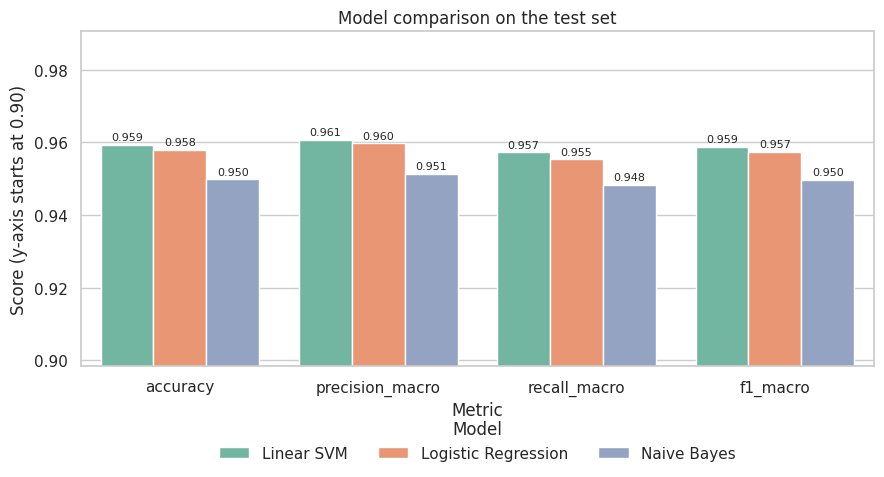

In [16]:
fig = evaluate.plot_model_comparison(results)
plt.show()

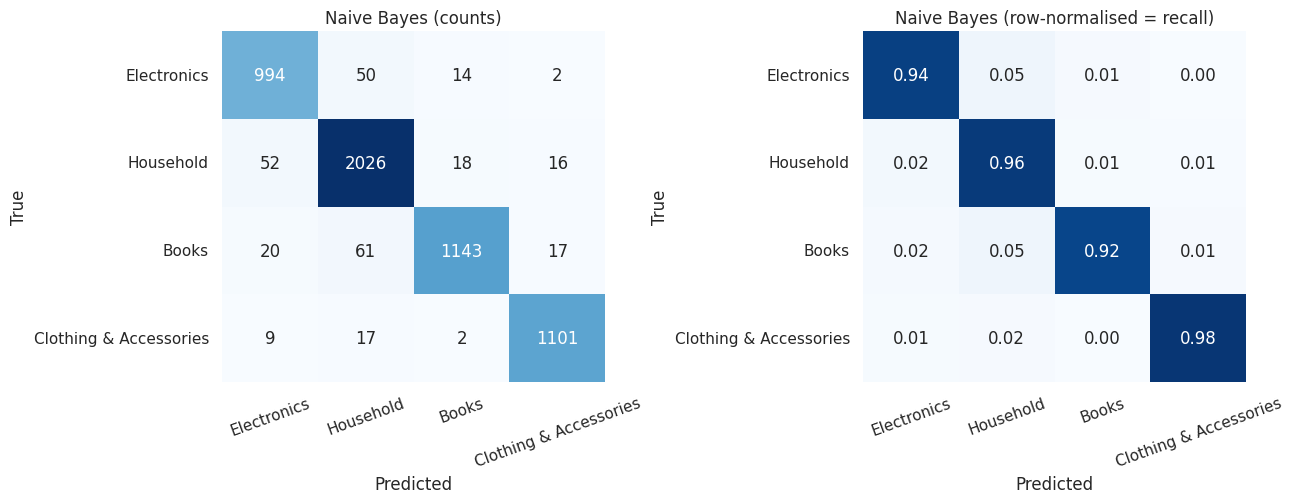

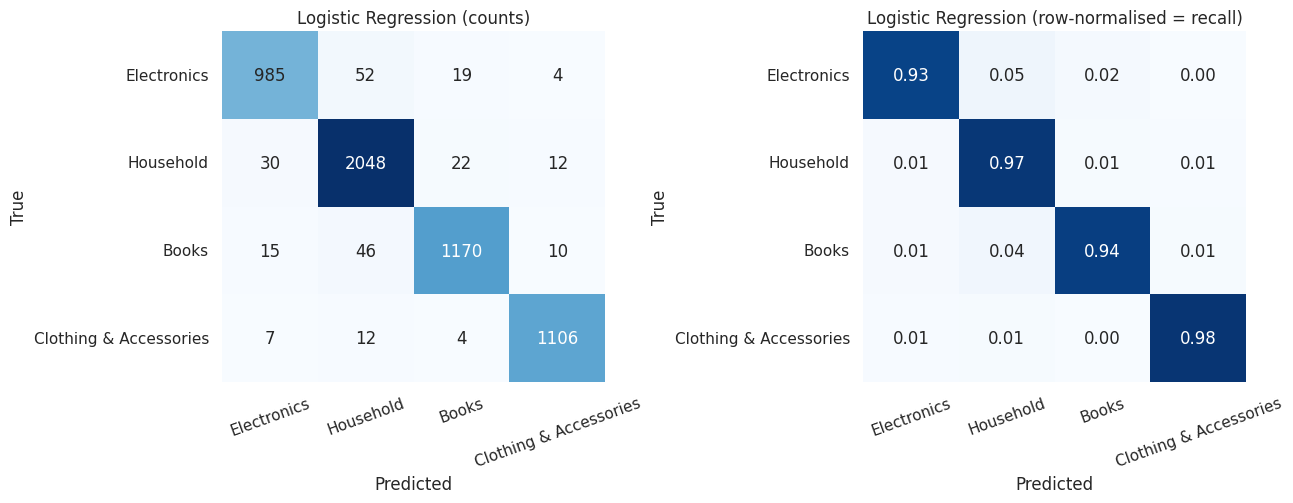

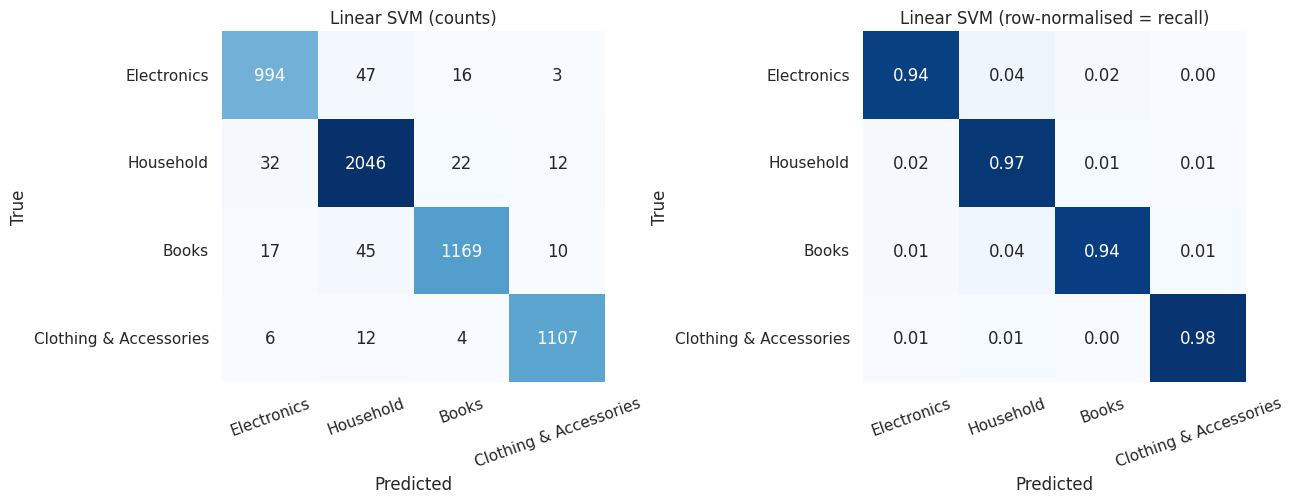

In [17]:
for name, y_pred in predictions.items():
    fig = evaluate.plot_confusion_matrix(y_test, y_pred, LABELS, title=name)
    plt.show()

## 10. Best-Model Selection
The best model is the one with the highest **macro-averaged F1-score on the test set** (ties are broken by accuracy). It is chosen only *after* the evaluation above and saved with `joblib`. The saved object is the complete pipeline, so it accepts raw product descriptions.

*Note:* the three models differ little in their candidate hyper-parameters (none were tuned), so choosing among only three models on the test set introduces a very small selection bias. The cross-validation column computed on the training data above gives an independent check.

In [18]:
best_name = evaluate.select_best_model(results, config.SELECTION_METRIC)
best_model = models[best_name]
display(Markdown(f"**Selection metric:** `{config.SELECTION_METRIC}`  \n**Best model:** {best_name}  \n"
                 f"**Macro F1:** {results.loc[best_name, 'f1_macro']:.4f}  |  "
                 f"**Accuracy:** {results.loc[best_name, 'accuracy']:.4f}"))

saved_path = train.save_model(best_model, config.MODELS_DIR / config.BEST_MODEL_FILENAME, {
    "model_name": best_name, "selection_metric": config.SELECTION_METRIC,
    "test_metrics": results.loc[best_name].round(4).to_dict(), "random_seed": RANDOM_SEED,
    "dataset_file": data_path.name, "rows_used": data_report["rows_final"]})

reloaded = predict.load_model(saved_path)
identical = bool((reloaded.predict(X_test) == best_model.predict(X_test)).all())
print(f"Saved to {saved_path.relative_to(ROOT)}  ({saved_path.stat().st_size / 1e6:.2f} MB)")
print("Reloaded model gives identical test predictions:", identical)

**Selection metric:** `f1_macro`  
**Best model:** Linear SVM  
**Macro F1:** 0.9589  |  **Accuracy:** 0.9592

Saved to models/best_model.joblib  (1.90 MB)
Reloaded model gives identical test predictions: True


## 11. Additional Analysis

### 11.1 Most informative features
For the linear models the terms with the largest positive coefficients for a class are the strongest evidence *for* that class. For Naive Bayes the score compares the term's log-probability in the class with its mean log-probability in the other classes.

In [19]:
display(Markdown(f"**Top 10 terms per class - {best_name}**"))
display(evaluate.top_features_per_class(best_model, 10))
if best_name != "Logistic Regression":
    display(Markdown("**Top 10 terms per class - Logistic Regression**"))
    display(evaluate.top_features_per_class(models["Logistic Regression"], 10))

**Top 10 terms per class - Linear SVM**

,Books,Clothing & Accessories,Electronics,Household
0,author,womens,camera,bathrobe
1,book,mens,laptop,door
2,fishing,girls,lens,chair
3,skateboard,boys,cable,vacuum
4,game,bra,screen,plastic
5,canoeing,sunglasses,projector,pillow
6,action,cotton,trail,bed
7,guide,women,bushing,watt
8,training,unisex,binoculars,lamp
9,review,wear,calculator,wallet


**Top 10 terms per class - Logistic Regression**

,Books,Clothing & Accessories,Electronics,Household
0,author,womens,camera,door
1,book,mens,laptop,home
2,fishing,girls,cable,set
3,guide,cotton,lens,plastic
4,game,boys,screen,chair
5,action,bra,compatible,watt
6,books,sunglasses,trail,kitchen
7,edition,women,speaker,vacuum
8,review,wear,black,bed
9,training,unisex,projector,lamp


### 11.2 Correct and incorrect predictions
Random examples from the test set (text shortened to 220 characters).

In [20]:
correct, wrong = evaluate.classification_examples(X_test, y_test, predictions[best_name], n=5, seed=RANDOM_SEED)
display(Markdown(f"**Correctly classified ({best_name})**"))
display(correct)
display(Markdown(f"**Misclassified ({best_name})**"))
display(wrong)

**Correctly classified (Linear SVM)**

,description,true,predicted
0,Mizago Women's Casual Full Sleeves White Rayon Shirt If you are looking for a unique and trendy casual shirt for wom...,Clothing & Accessories,Clothing & Accessories
1,Generic Zipper Foot for Home Machine (Right and Left) - Set of 2 Pressure foot for home sewing machine. It is suitab...,Household,Household
2,"Bianca Sonoma 12 Piece 450 GSM Cotton Face Towel Set - Wine, Gold and Brown Color Name:Wine, Gold and Brown Bianca...",Household,Household
3,Morphy Richards InstaCook 1200-Watt Electric Kettle Cooking healthy and smart is the need of the hour. Morphy Richar...,Household,Household
4,"Maniac Men's Cotton T-Shirt (Men-Ss18-Thumb-Ring-07) To perfect an easy going look, you must get this printed black ...",Clothing & Accessories,Clothing & Accessories


**Misclassified (Linear SVM)**

,description,true,predicted
0,Streetkart Women's & Girl's Traditional Kutchi Art Work Sling Bag/Fashionable Sling Bag for Women/Stylish Polyester ...,Household,Clothing & Accessories
1,Adonai Instant Heating Water Tap (White) Surface/Basin Mount ADONAI brings to you this ultra modern european style i...,Electronics,Household
2,Lifelong LLCF07 1200 mm High Speed Ceiling Fan (Brown) Color Name:Brown Take a break from the summer heat in style...,Electronics,Household
3,"Camera Lens Plastic Coffee Mug with Lid, 350ml, Black Perfect gifting option for your loved ones. If you have friend...",Electronics,Household
4,"Interactive Agro Vermicompost, Made from Cow Manure, 100 Percent Organic (12KG) (2X6KG) Display Weight:12.0 Kilogram...",Books,Household


In [21]:
display(Markdown(f"**Per-class scores - {best_name}**"))
display(evaluate.per_class_report(y_test, predictions[best_name], LABELS).round(4))
pair = evaluate.most_confused_pair(y_test, predictions[best_name], LABELS)
if pair:
    print(f"Most frequent confusion: true '{pair[0]}' predicted as '{pair[1]}' ({pair[2]} test samples)")

**Per-class scores - Linear SVM**

,precision,recall,f1-score,support
Electronics,0.9476,0.9377,0.9426,1060.0
Household,0.9516,0.9688,0.9601,2112.0
Books,0.9653,0.9420,0.9535,1241.0
Clothing & Accessories,0.9779,0.9805,0.9792,1129.0
macro avg,0.9606,0.9572,0.9589,5542.0
weighted avg,0.9593,0.9592,0.9592,5542.0


Most frequent confusion: true 'Electronics' predicted as 'Household' (47 test samples)


## 12. Example Predictions
The six descriptions below were **written for this demonstration**. They are *illustrative examples*, **not records from the dataset**, and they are not evidence of model performance. The model returns probabilities (Naive Bayes, Logistic Regression) or SVM decision values (LinearSVC).

In [22]:
rows = []
for title, text in predict.EXAMPLE_DESCRIPTIONS.items():
    out = predict.predict_text(best_model, text)
    top = max(out["scores"], key=out["scores"].get) if out["scores"] else None
    rows.append({"example (illustrative)": title, "predicted category": out["label"],
                 out["score_type"]: round(out["scores"][top], 3) if top else None})
display(pd.DataFrame(rows))

custom = "Stainless steel water bottle, 1 litre, keeps drinks cold for 24 hours"
print("\nCustom input:", custom)
print(predict.predict_text(best_model, custom))

,example (illustrative),predicted category,decision value
0,Wireless headphones,Electronics,0.068
1,Cookware set,Household,1.594
2,Novel,Books,1.280
3,Cotton t-shirt,Clothing & Accessories,1.366
4,Smart watch,Electronics,0.328
5,Bed sheet,Household,1.559



Custom input: Stainless steel water bottle, 1 litre, keeps drinks cold for 24 hours
{'label': 'Household', 'scores': {'Books': -0.8941580745897533, 'Clothing & Accessories': -1.1311828469905874, 'Electronics': -1.1455027881964064, 'Household': 0.9451237958052373}, 'score_type': 'decision value'}


## 13. Conclusions

In [23]:
ranking = results["f1_macro"].sort_values(ascending=False)
per_class = evaluate.per_class_report(y_test, predictions[best_name], LABELS).loc[LABELS]
weakest = per_class["f1-score"].idxmin()
strongest = per_class["f1-score"].idxmax()
spread = ranking.iloc[0] - ranking.iloc[-1]
lines = [
    f"- **Data.** {data_report['rows_final']:,} of {data_report['rows_initial']:,} records were used; "
    f"{data_report['rows_removed_total']:,} ({data_report['percent_removed']}%) were removed, of which "
    f"{data_report['removed_exact_duplicates']:,} were exact duplicate records.",
    "- **Ranking by macro F1 (test set):** " + ", ".join(f"{n} ({v:.4f})" for n, v in ranking.items()) + ".",
    f"- **Best model:** {best_name}. The gap between the best and the weakest model is {spread:.4f} macro F1.",
    f"- **Easiest class:** {strongest} (F1 {per_class.loc[strongest, 'f1-score']:.4f}). "
    f"**Hardest class:** {weakest} (F1 {per_class.loc[weakest, 'f1-score']:.4f}).",
]
if pair:
    lines.append(f"- **Most frequent confusion:** '{pair[0]}' predicted as '{pair[1]}' ({pair[2]} test samples).")
display(Markdown("\n".join(lines)))

- **Data.** 27,709 of 50,425 records were used; 22,716 (45.05%) were removed, of which 22,622 were exact duplicate records.
- **Ranking by macro F1 (test set):** Linear SVM (0.9589), Logistic Regression (0.9574), Naive Bayes (0.9496).
- **Best model:** Linear SVM. The gap between the best and the weakest model is 0.0092 macro F1.
- **Easiest class:** Clothing & Accessories (F1 0.9792). **Hardest class:** Electronics (F1 0.9426).
- **Most frequent confusion:** 'Electronics' predicted as 'Household' (47 test samples).

**Why can the models differ?** Naive Bayes assumes that words are independent given the class, an assumption that is clearly violated by real text. It is, however, very fast and robust. Logistic Regression and the linear SVM are *discriminative*: they learn weights that directly separate the classes and do not need the independence assumption, which often gives them an advantage on TF-IDF features. The table in Section 9 shows whether this pattern holds for this dataset; the differences should be read together with the cross-validation column, because small gaps can be within random variation.

**Limitations.**
- The data comes from Indian e-commerce websites. Style, vocabulary and price information may not transfer to other markets or languages.
- The classes are imbalanced (Household is the largest class), so accuracy alone can hide weak performance on smaller classes.
- Only four coarse categories exist. Real catalogues use hundreds of fine-grained categories.
- Some descriptions are ambiguous or mislabelled (for example accessories that could be Electronics or Household), which puts a ceiling on the achievable score.
- TF-IDF ignores word order beyond bigrams and cannot capture meaning, synonyms or unseen words.
- Hyper-parameters were not tuned, and a single train-test split was used for the final comparison.

**Possible improvements.**
- Tune `C`, `alpha`, the n-gram range and the vocabulary size with cross-validation on the training set.
- Try `class_weight="balanced"` and add character n-grams to handle spelling variants.
- Optional extension (not a replacement for TF-IDF): dense features from Word2Vec or sentence embeddings, or a fine-tuned transformer model.
- Perform error analysis on misclassified products to find labelling problems and add rules or more data for confusable classes.
- Evaluate on a second, independent dataset to measure generalisation.